# Advanced level — barren plateaus

The advanced target is a portfolio, or the same binary problem, large enough that training itself becomes the obstacle ($n \gtrsim 25$). This notebook isolates that obstacle.

A **barren plateau** is not a single flat point. It is a statement about random parameters. Draw $\theta$ at random and look at one partial derivative of a cost $C(\theta)=\langle \psi(\theta)|H|\psi(\theta)\rangle$. On a plateau,

$$
\mathrm{Var}_\theta\big(\partial_{\theta_k} C\big) \in O(b^{-n})
$$

for some $b>1$, here about $2$. The typical gradient is then the square root of that, $O(2^{-n/2})$. A polynomial number of shots cannot tell the sign of a quantity that small, and derivative-free methods such as COBYLA fail for the same reason: the cost values concentrate too.

Three separate mechanisms do this:

1. **Global cost.** $H=Z^{\otimes n}$ has a plateau on a shallow circuit already (Cerezo et al., 2021).
2. **Deep random ansatz.** A hardware-efficient circuit that is deep enough to look like a unitary 2-design has a plateau even for a local $H$ (McClean et al., 2018).
3. **Noise.** A local depolarizing channel after every layer drives the state toward the maximally mixed state, so the gradient dies with depth even at fixed $n$ (Wang et al., 2021).

A zero derivative because the parameter never reaches the measured qubit is a light-cone fact, not a plateau. Every gradient below is $\partial/\partial\theta$ of the first $R_Y$ on qubit 0, and the local cost is $\langle Z_0\rangle$, so that gate sits inside the light cone.


## 1. Ansatz, costs, and the parameter-shift rule

The ansatz is the standard hardware-efficient circuit. Layer $\ell$ is an $R_Y R_Z$ on every qubit, then a brickwork of CNOTs: even layers connect $(0,1),(2,3),\ldots$ and odd layers connect $(1,2),(3,4),\ldots$.

$$
R_Y(\theta)=\exp(-i\theta Y/2).
$$

For a gate of that form the derivative of a Pauli expectation is exact:

$$
\partial_\theta \langle H\rangle = \frac{1}{2}\Big(\langle H\rangle_{\theta+\pi/2} - \langle H\rangle_{\theta-\pi/2}\Big).
$$

The two costs are

$$
C_{\mathrm{global}}=\langle Z^{\otimes n}\rangle, \qquad C_{\mathrm{local}}=\langle Z_0\rangle.
$$

In Qiskit the rightmost letter of a Pauli string is qubit 0, so $\langle Z_0\rangle$ is the string $I^{\otimes(n-1)}Z$.


In [ ]:
import numpy as np
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector, SparsePauliOp

def hardware_efficient(n, depth, theta):
    angles = np.asarray(theta, dtype=float).reshape(depth, n, 2)
    qc = QuantumCircuit(n)
    for layer in range(depth):
        for qubit in range(n):
            qc.ry(angles[layer, qubit, 0], qubit)
            qc.rz(angles[layer, qubit, 1], qubit)
        start = 0 if layer % 2 == 0 else 1
        for qubit in range(start, n - 1, 2):
            qc.cx(qubit, qubit + 1)
    return qc

def cost_operator(n, global_cost):
    if global_cost:
        return SparsePauliOp("Z" * n)
    return SparsePauliOp("I" * (n - 1) + "Z")

def partial(n, depth, theta, global_cost):
    """Parameter-shift derivative of the first RY on qubit 0."""
    operator = cost_operator(n, global_cost)
    base = np.asarray(theta, dtype=float)

    def energy(shift):
        trial = base.copy()
        trial.ravel()[0] += shift
        state = Statevector(hardware_efficient(n, depth, trial))
        return float(state.expectation_value(operator).real)

    return 0.5 * (energy(np.pi / 2) - energy(-np.pi / 2))

def gradient_variance(n, depth, global_cost, samples, seed):
    rng = np.random.default_rng(seed)
    gradients = np.empty(samples)
    for sample in range(samples):
        theta = rng.uniform(0.0, 2.0 * np.pi, size=(depth, n, 2))
        gradients[sample] = partial(n, depth, theta, global_cost)
    return float(gradients.var()), float(np.mean(np.abs(gradients)))

# RY(theta)|0> has <Z> = cos(theta), so the derivative at pi/2 is -1.
one = partial(1, 1, np.array([np.pi / 2, 0.0]), global_cost=True)
print(f"parameter shift at n=1, theta=pi/2 : {one:.6f}")
assert abs(one + 1.0) < 1e-9


parameter shift at n=1, theta=pi/2 : -1.000000


## 2. A global cost plateaus at depth 2

Depth is fixed at 2. Only $n$ changes. Thirty-two random initializations estimate the variance. The dashed line is $2^{-(n-n_0)}$ matched to the global cost at $n=4$. A slope near $-1$ on the $\log_2$ plot means the variance is cut in half by every added qubit.


   n   var global   |g| global    var local    |g| local
   4    6.640e-02    1.983e-01    2.943e-01    5.259e-01
   6    1.002e-02    6.746e-02    2.399e-01    4.094e-01
   8    4.615e-03    3.647e-02    2.505e-01    4.329e-01
  10    1.175e-03    1.854e-02    2.214e-01    4.053e-01
  12    1.670e-04    7.450e-03    2.633e-01    4.220e-01
slope of log2(var global) versus n : -1.02 per qubit
shots to match the n=12 global gradient : about 5987


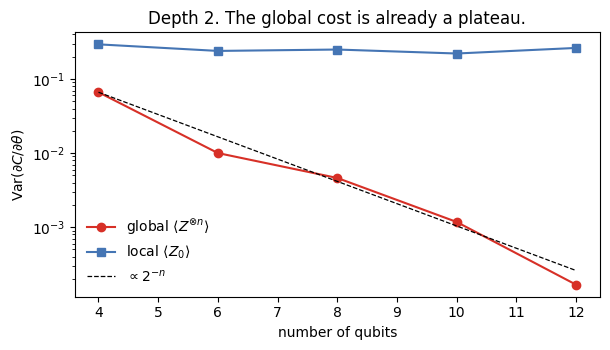

In [ ]:
import matplotlib.pyplot as plt

SIZES = [4, 6, 8, 10, 12]
SAMPLES = 32

shallow = {}
for global_cost, name in [(True, "global"), (False, "local")]:
    shallow[name] = np.array([
        gradient_variance(n, depth=2, global_cost=global_cost, samples=SAMPLES, seed=1000 + n)
        for n in SIZES
    ])

global_var = shallow["global"][:, 0]
slope = np.polyfit(SIZES, np.log2(global_var), 1)[0]
reference = global_var[0] * 2.0 ** (-(np.array(SIZES) - SIZES[0]))

print(f"{'n':>4} {'var global':>12} {'|g| global':>12} {'var local':>12} {'|g| local':>12}")
for n, g_row, l_row in zip(SIZES, shallow["global"], shallow["local"]):
    print(f"{n:4d} {g_row[0]:12.3e} {g_row[1]:12.3e} {l_row[0]:12.3e} {l_row[1]:12.3e}")
print(f"slope of log2(var global) versus n : {slope:.2f} per qubit")
print(f"shots to match the n=12 global gradient : about {1.0 / shallow['global'][-1, 0]:.0f}")

fig, ax = plt.subplots(figsize=(6.2, 3.6))
ax.semilogy(SIZES, shallow["global"][:, 0], "o-", color="#d73027", label=r"global $\langle Z^{\otimes n}\rangle$")
ax.semilogy(SIZES, shallow["local"][:, 0], "s-", color="#4575b4", label=r"local $\langle Z_0\rangle$")
ax.semilogy(SIZES, reference, "--", color="black", lw=0.9, label=r"$\propto 2^{-n}$")
ax.set_xlabel("number of qubits")
ax.set_ylabel(r"$\mathrm{Var}(\partial C/\partial\theta)$")
ax.set_title("Depth 2. The global cost is already a plateau.")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()


The local variance stays near $0.25$ from 4 to 12 qubits. The global variance falls with slope $-1.02$ per qubit, which is $2^{-n}$. At 12 qubits the mean absolute global gradient is $7.5	imes 10^{-3}$ and the variance is $1.7	imes 10^{-4}$, so a few thousand shots are the budget for one partial derivative. At $n=25$ the same slope leaves a typical gradient near $2^{-12}$, and the shot count is exponential. Adding shots does not remove a barren plateau.

This is also why the intermediate portfolio circuit could be trained. It is depth 2, its rotations are seeded by the marginal scores rather than drawn at random, and the loss scores whole portfolios. It is on the local, shallow side of this plot, not the global side.


## 3. A local cost plateaus once the circuit is deep

The same two costs, now with depth equal to $n$. The circuit is expressive enough that even $\langle Z_0\rangle$ starts to concentrate. Locality of $H$ is not a remedy after the ansatz has become a scramble.


   n   var global    var local
   4    1.975e-02    1.198e-01
   6    6.970e-03    5.949e-02
   8    1.209e-03    3.445e-02
  10    4.515e-04    3.023e-02
  12    1.115e-04    1.809e-02


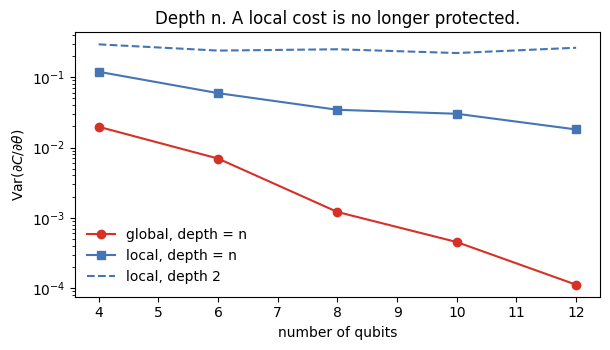

In [ ]:
deep = {}
for global_cost, name in [(True, "global"), (False, "local")]:
    deep[name] = np.array([
        gradient_variance(n, depth=n, global_cost=global_cost, samples=SAMPLES, seed=2000 + n)
        for n in SIZES
    ])

print(f"{'n':>4} {'var global':>12} {'var local':>12}")
for n, g_row, l_row in zip(SIZES, deep["global"], deep["local"]):
    print(f"{n:4d} {g_row[0]:12.3e} {l_row[0]:12.3e}")

fig, ax = plt.subplots(figsize=(6.2, 3.6))
ax.semilogy(SIZES, deep["global"][:, 0], "o-", color="#d73027", label="global, depth = n")
ax.semilogy(SIZES, deep["local"][:, 0], "s-", color="#4575b4", label="local, depth = n")
ax.semilogy(SIZES, shallow["local"][:, 0], "--", color="#4575b4", label="local, depth 2")
ax.set_xlabel("number of qubits")
ax.set_ylabel(r"$\mathrm{Var}(\partial C/\partial\theta)$")
ax.set_title("Depth n. A local cost is no longer protected.")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()


## 4. Noise does it at fixed $n$

Mechanisms 1 and 2 are properties of the unitary circuit. A device adds a third one. Here $n=6$ is fixed and the cost is the local $\langle Z_0\rangle$. After every layer, each qubit gets a depolarizing channel of strength $p=0.05$:

$$
\mathcal{E}(\rho)=(1-p)\rho+\frac{p}{3}\big(X\rho X+Y\rho Y+Z\rho Z\big).
$$

The parameter-shift rule still holds, because the channel does not depend on $\theta$ and the derivative is linear. What changes is the state the channel is applied to. Each layer multiplies the off-diagonal information by $(1-p)$, so a gradient that has to travel through $L$ noisy layers shrinks as $(1-p)^{cL}$.


n = 6, local cost
 depth      var p=0   var p=0.05
     1    4.703e-01    4.972e-01
     2    2.733e-01    1.808e-01
     4    1.936e-01    1.368e-01
     8    2.554e-02    1.764e-02
    12    2.213e-02    2.068e-03


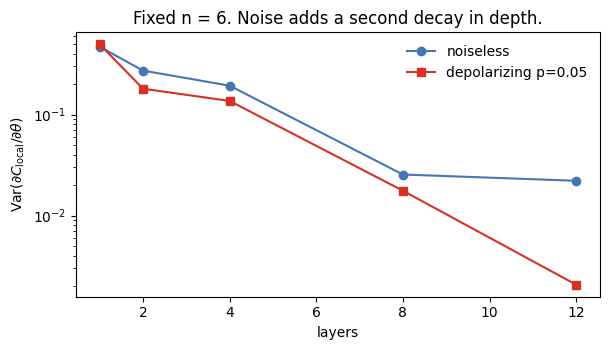

In [ ]:
from qiskit.quantum_info import DensityMatrix, Kraus, Operator
from qiskit.circuit.library import RYGate, RZGate, CXGate

def depolarizing(p):
    identity = np.eye(2, dtype=complex)
    return Kraus([
        np.sqrt(1.0 - p) * identity,
        np.sqrt(p / 3.0) * Operator.from_label("X").data,
        np.sqrt(p / 3.0) * Operator.from_label("Y").data,
        np.sqrt(p / 3.0) * Operator.from_label("Z").data,
    ])

def noisy_partial(n, depth, theta, p, channel):
    operator = cost_operator(n, global_cost=False)
    base = np.asarray(theta, dtype=float)

    def energy(shift):
        trial = base.copy()
        trial.ravel()[0] += shift
        angles = trial.reshape(depth, n, 2)
        rho = DensityMatrix.from_label("0" * n)
        for layer in range(depth):
            for qubit in range(n):
                rho = rho.evolve(RYGate(float(angles[layer, qubit, 0])), [qubit])
                rho = rho.evolve(RZGate(float(angles[layer, qubit, 1])), [qubit])
            start = 0 if layer % 2 == 0 else 1
            for qubit in range(start, n - 1, 2):
                rho = rho.evolve(CXGate(), [qubit, qubit + 1])
            if p > 0.0:
                for qubit in range(n):
                    rho = rho.evolve(channel, [qubit])
        return float(np.real(rho.expectation_value(operator)))

    return 0.5 * (energy(np.pi / 2) - energy(-np.pi / 2))

def noisy_variance(n, depth, p, samples, seed):
    rng = np.random.default_rng(seed)
    channel = depolarizing(p) if p > 0.0 else None
    gradients = np.empty(samples)
    for sample in range(samples):
        theta = rng.uniform(0.0, 2.0 * np.pi, size=(depth, n, 2))
        gradients[sample] = noisy_partial(n, depth, theta, p, channel)
    return float(gradients.var())

NOISE_N = 6
NOISE_DEPTHS = [1, 2, 4, 8, 12]
NOISE_P = 0.05
unitary_var = [noisy_variance(NOISE_N, depth, 0.0, samples=16, seed=3000 + depth) for depth in NOISE_DEPTHS]
noisy_var = [noisy_variance(NOISE_N, depth, NOISE_P, samples=16, seed=4000 + depth) for depth in NOISE_DEPTHS]

print(f"n = {NOISE_N}, local cost")
print(f"{'depth':>6} {'var p=0':>12} {'var p=0.05':>12}")
for depth, clean, noisy in zip(NOISE_DEPTHS, unitary_var, noisy_var):
    print(f"{depth:6d} {clean:12.3e} {noisy:12.3e}")

fig, ax = plt.subplots(figsize=(6.2, 3.6))
ax.semilogy(NOISE_DEPTHS, unitary_var, "o-", color="#4575b4", label="noiseless")
ax.semilogy(NOISE_DEPTHS, noisy_var, "s-", color="#d73027", label=f"depolarizing p={NOISE_P}")
ax.set_xlabel("layers")
ax.set_ylabel(r"$\mathrm{Var}(\partial C_{\mathrm{local}}/\partial\theta)$")
ax.set_title("Fixed n = 6. Noise adds a second decay in depth.")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()


## What to take from the three plots

A barren plateau is exponential concentration of the gradient over random $\theta$. The plots separate the causes:

- At depth 2 the **global** cost decays as about $2^{-n}$. The **local** cost does not.
- Setting the depth equal to $n$ pulls the local cost down as well. A local Hamiltonian does not save a deep random ansatz.
- At fixed $n=6$, raising the depth concentrates $\langle Z_0\rangle$ even without noise, because the early rotation is scrambled by later layers. Depolarizing noise of 5% per qubit per layer makes that decay steeper.

What keeps a variational portfolio trainable, as in the intermediate notebook:

- Keep the circuit shallow, and entangle only the pairs the cost actually couples.
- Do not initialize every angle uniformly at random. The feature-map $R_Y$ starts the search at the marginal greedy portfolio.
- Do not use one global Pauli as a stand-in for $f(x)$ when a sum of few-qubit terms, or the portfolio loss itself, can be evaluated.

Growing the same random hardware-efficient circuit toward 25 or 156 qubits does not produce a gradient a device can measure. The shot cost tracks $1/\mathrm{Var}(\partial C)$, which is exponential in $n$ for the global cost. This entire scan is a noiseless statevector, plus an exact density matrix for the noise section. It is a trainability result, not a quantum advantage.
